# IPL AUCTION 2023

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Loading DATASET

In [2]:
data=pd.read_csv(r"IPL_Squad_2023_Auction_Dataset.csv")
data

,Unnamed: 0,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,0,Shivam Mavi,4000000,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,1,Joshua Little,5000000,BOWLER,4.4,528.0,NaN,Gujarat Titans
2,2,Kane Williamson,20000000,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,3,K.S. Bharat,2000000,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,4,Mohit Sharma,5000000,BOWLER,0.5,60.0,NaN,Gujarat Titans
...,...,...,...,...,...,...,...,...
563,563,Dhruv Patel,2000000,ALL-ROUNDER,NaN,NaN,NaN,Unsold
564,564,Jack Prestwidge,2000000,ALL-ROUNDER,NaN,NaN,NaN,Unsold
565,565,Aditya Sarvate,2000000,ALL-ROUNDER,NaN,NaN,NaN,Unsold
566,566,Sagar Solanki,2000000,ALL-ROUNDER,NaN,NaN,NaN,Unsold


### Dropping unnecessary columns

In [3]:
data.drop('Unnamed: 0', axis = 1, inplace = True)

In [4]:
data.head()

,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,Shivam Mavi,4000000,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,Joshua Little,5000000,BOWLER,4.4,528.0,NaN,Gujarat Titans
2,Kane Williamson,20000000,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,K.S. Bharat,2000000,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,Mohit Sharma,5000000,BOWLER,0.5,60.0,NaN,Gujarat Titans


### Basic Analysis

In [5]:
data.describe()

,COST IN ₹ (CR.),Cost IN $ (000)
count,243.000000,243.000000
mean,0.687243,82.469136
std,2.511700,301.404032
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.200000,24.000000
max,18.500000,2220.000000


In [6]:
data.dtypes

Player's List       object
Base Price          object
TYPE                object
COST IN ₹ (CR.)    float64
Cost IN $ (000)    float64
2022 Squad          object
Team                object
dtype: object

In [7]:
data.isna().sum()

Player's List        0
Base Price           0
TYPE                 0
COST IN ₹ (CR.)    325
Cost IN $ (000)    325
2022 Squad         338
Team                 0
dtype: int64

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568 entries, 0 to 567
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Player's List    568 non-null    object 
 1   Base Price       568 non-null    object 
 2   TYPE             568 non-null    object 
 3   COST IN ₹ (CR.)  243 non-null    float64
 4   Cost IN $ (000)  243 non-null    float64
 5   2022 Squad       230 non-null    object 
 6   Team             568 non-null    object 
dtypes: float64(2), object(5)
memory usage: 31.2+ KB


In [9]:
data.count()

Player's List      568
Base Price         568
TYPE               568
COST IN ₹ (CR.)    243
Cost IN $ (000)    243
2022 Squad         230
Team               568
dtype: int64

In [10]:
data.shape

(568, 7)

In [11]:

data = data[pd.to_numeric(data['Base Price'], errors='coerce').notna()]

In [12]:
#data['Base Price'] = data['Base Price'].astype(float)
data.loc[:, 'Base Price'] = data['Base Price'].astype(float)
data


,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,Shivam Mavi,4000000.0,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,Joshua Little,5000000.0,BOWLER,4.4,528.0,NaN,Gujarat Titans
2,Kane Williamson,20000000.0,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,K.S. Bharat,2000000.0,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,Mohit Sharma,5000000.0,BOWLER,0.5,60.0,NaN,Gujarat Titans
...,...,...,...,...,...,...,...
563,Dhruv Patel,2000000.0,ALL-ROUNDER,NaN,NaN,NaN,Unsold
564,Jack Prestwidge,2000000.0,ALL-ROUNDER,NaN,NaN,NaN,Unsold
565,Aditya Sarvate,2000000.0,ALL-ROUNDER,NaN,NaN,NaN,Unsold
566,Sagar Solanki,2000000.0,ALL-ROUNDER,NaN,NaN,NaN,Unsold


In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 405 entries, 0 to 567
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Player's List    405 non-null    object 
 1   Base Price       405 non-null    object 
 2   TYPE             405 non-null    object 
 3   COST IN ₹ (CR.)  80 non-null     float64
 4   Cost IN $ (000)  80 non-null     float64
 5   2022 Squad       67 non-null     object 
 6   Team             405 non-null    object 
dtypes: float64(2), object(5)
memory usage: 25.3+ KB


The players who went unsold and the players who did not play last year IPL has got null values

### Data Cleaning

In [14]:
# Replacing null values
#data['COST IN ₹ (CR.)'] = data['COST IN ₹ (CR.)'].fillna(0)
#data['Cost IN $ (000)']=  data['Cost IN $ (000)'].fillna(0)

data.loc[:, 'COST IN ₹ (CR.)'] = data['COST IN ₹ (CR.)'].fillna(0)
data.loc[:, 'Cost IN $ (000)'] = data['Cost IN $ (000)'].fillna(0)

#data['COST IN ₹ (CR.)'].fillna(0, inplace = True)
#data['Cost IN $ (000)'].fillna(0, inplace = True)

In [15]:
# Replacing Null values of 2022 Squad column with DNP as the players did not play 2022 IPL Season
#data['2022 Squad'].fillna('DNP', inplace = True)
#data['2022 Squad']= data['2022 Squad'].fillna('DNP')
data.loc[:, '2022 Squad'] = data['2022 Squad'].fillna('DNP')


### Verifying changes

In [16]:


data.isnull().sum()

Player's List      0
Base Price         0
TYPE               0
COST IN ₹ (CR.)    0
Cost IN $ (000)    0
2022 Squad         0
Team               0
dtype: int64

In [17]:
data.head()

,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
0,Shivam Mavi,4000000.0,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,Joshua Little,5000000.0,BOWLER,4.4,528.0,DNP,Gujarat Titans
2,Kane Williamson,20000000.0,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,K.S. Bharat,2000000.0,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,Mohit Sharma,5000000.0,BOWLER,0.5,60.0,DNP,Gujarat Titans


Hence Values are replaced and our Data is Cleaned for further Analysis

### Q1) List of players with base price above 1.5 crores

In [18]:

df_above_15m = data[data['Base Price'] > 15000000].copy()


In [19]:

df_above_15m 

,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
2,Kane Williamson,20000000.0,BATSMAN,2.00,240.0,SRH,Gujarat Titans
25,Ben Stokes,20000000.0,ALL-ROUNDER,16.25,1950.0,DNP,Chennai Super Kings
51,Rilee Rossouw,20000000.0,BATSMAN,4.60,552.0,DNP,Delhi Capitals
53,Phil Salt,20000000.0,WICKETKEEPER,2.00,240.0,DNP,Delhi Capitals
97,Sam Curran,20000000.0,ALL-ROUNDER,18.50,2220.0,DNP,Punjab Super Kings
119,Nicholas Pooran,20000000.0,WICKETKEEPER,16.00,1920.0,SRH,Lucknow Super Giants
144,Cameron Green,20000000.0,ALL-ROUNDER,17.50,2100.0,DNP,Mumbai Indians
193,Jason Holder,20000000.0,ALL-ROUNDER,5.75,690.0,LSG,Rajasthan Royals
222,Adil Rashid,20000000.0,BOWLER,2.00,240.0,DNP,Sunrisers Hyderabad
243,Tom Banton,20000000.0,WICKETKEEPER,0.00,0.0,DNP,Unsold


### Q2) List of players with base price above 50 lacks and below 1.5 crores

In [20]:
df_below_15m = data[(data['Base Price'] < 15000000) & (data['Base Price'] > 5000000)].copy()

In [21]:

df_below_15m

,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
26,Kyle Jamieson,10000000.0,BOWLER,1.00,120.0,DNP,Chennai Super Kings
52,Manish Pandey,10000000.0,BATSMAN,2.40,288.0,LSG,Delhi Capitals
76,David Wiese,10000000.0,ALL-ROUNDER,1.00,120.0,DNP,Kolkata Knight Riders
120,Daniel Sams,7500000.0,ALL-ROUNDER,0.75,90.0,MI,Lucknow Super Giants
169,Reece Topley,7500000.0,BOWLER,1.90,228.0,DNP,Royal Challengers Banglore
195,Joe Root,10000000.0,BATSMAN,1.00,120.0,DNP,Rajasthan Royals
219,Mayank Agarwal,10000000.0,BATSMAN,8.25,990.0,PBKS,Sunrisers Hyderabad
220,Heinrich Klaasen,10000000.0,WICKETKEEPER,5.25,630.0,DNP,Sunrisers Hyderabad
224,Akeal Hosein,10000000.0,BOWLER,1.00,120.0,DNP,Sunrisers Hyderabad
247,Mujeeb Rahman,10000000.0,BOWLER,0.00,0.0,DNP,Unsold


### Q3) Top 10 Expensive Players sold

In [22]:

top_10_expensive_batsmen = data.nlargest(10, 'COST IN ₹ (CR.)')[["Player's List", 'COST IN ₹ (CR.)']]

In [23]:


top_10_expensive_batsmen

,Player's List,COST IN ₹ (CR.)
97,Sam Curran,18.50
144,Cameron Green,17.50
25,Ben Stokes,16.25
119,Nicholas Pooran,16.00
218,Harry Brook,13.25
219,Mayank Agarwal,8.25
0,Shivam Mavi,6.00
193,Jason Holder,5.75
50,Mukesh Kumar,5.50
220,Heinrich Klaasen,5.25


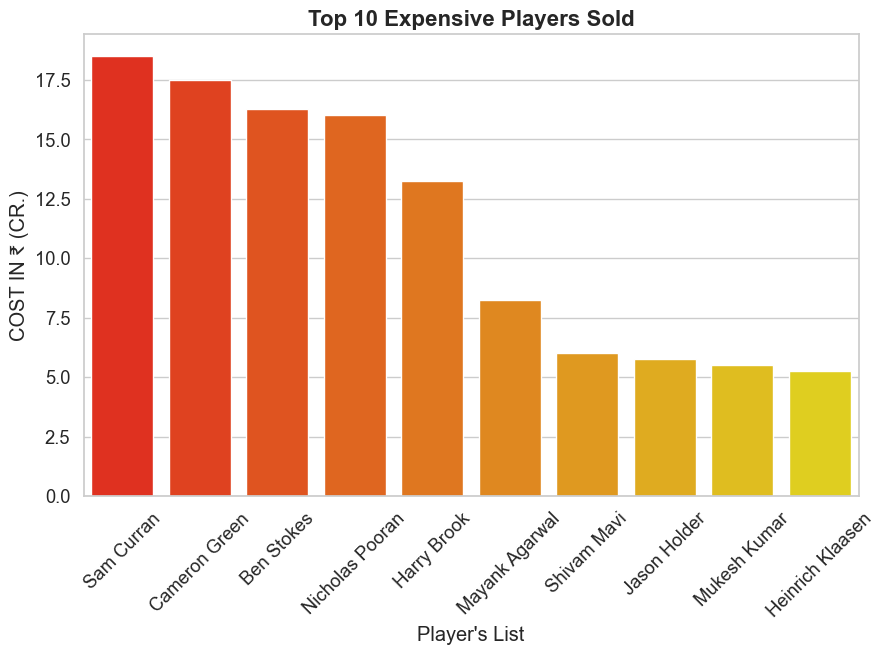

In [24]:

sns.set_theme(style='whitegrid', font_scale=1.2)

plt.figure(figsize=(10, 6))  
#sns.barplot(data=top_10_expensive_batsmen, x="Player's List", y='COST IN ₹ (CR.)', dodge = False, palette = 'autumn')
sns.barplot(data=top_10_expensive_batsmen,x="Player's List",y='COST IN ₹ (CR.)',dodge=False,hue="Player's List",   # assign hue
    palette='autumn',
    legend=False           # suppress legend
)


plt.xlabel("Player's List")
plt.ylabel('COST IN ₹ (CR.)')

plt.title('Top 10 Expensive Players Sold', fontweight='bold', fontsize=16)

plt.xticks(rotation=45)


plt.show()


### Q4) Top 5 expensive WicketKeepers sold

In [25]:
filtered_data = data[data['TYPE'] == 'WICKETKEEPER']
sorted_data = filtered_data.sort_values(by='COST IN ₹ (CR.)', ascending=False)
top_5_expensive_wk = sorted_data.head()


In [26]:

top_5_expensive_wk

,Player's List,Base Price,TYPE,COST IN ₹ (CR.),Cost IN $ (000),2022 Squad,Team
119,Nicholas Pooran,20000000.0,WICKETKEEPER,16.00,1920.0,SRH,Lucknow Super Giants
220,Heinrich Klaasen,10000000.0,WICKETKEEPER,5.25,630.0,DNP,Sunrisers Hyderabad
53,Phil Salt,20000000.0,WICKETKEEPER,2.00,240.0,DNP,Delhi Capitals
3,K.S. Bharat,2000000.0,WICKETKEEPER,1.20,144.0,DC,Gujarat Titans
77,N. Jagadeesan,2000000.0,WICKETKEEPER,0.90,108.0,CSK,Kolkata Knight Riders


In [27]:
top_5_expensive_wk = top_5_expensive_wk.rename(columns={"Player's List": 'Name'})

top_5_expensive_wk = top_5_expensive_wk.rename(columns={"COST IN ₹ (CR.)": 'Cost'})
     

In [28]:
top_5_expensive_wk

,Name,Base Price,TYPE,Cost,Cost IN $ (000),2022 Squad,Team
119,Nicholas Pooran,20000000.0,WICKETKEEPER,16.00,1920.0,SRH,Lucknow Super Giants
220,Heinrich Klaasen,10000000.0,WICKETKEEPER,5.25,630.0,DNP,Sunrisers Hyderabad
53,Phil Salt,20000000.0,WICKETKEEPER,2.00,240.0,DNP,Delhi Capitals
3,K.S. Bharat,2000000.0,WICKETKEEPER,1.20,144.0,DC,Gujarat Titans
77,N. Jagadeesan,2000000.0,WICKETKEEPER,0.90,108.0,CSK,Kolkata Knight Riders


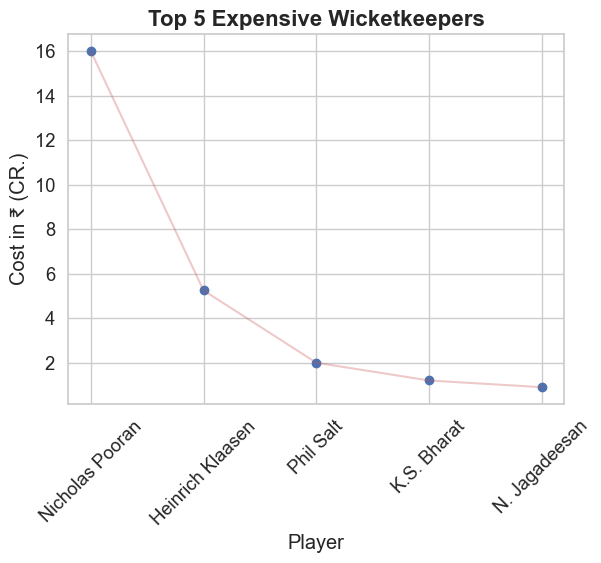

In [29]:

name = top_5_expensive_wk['Name']
cost = top_5_expensive_wk['Cost']

plt.scatter(name, cost)

plt.xlabel('Player')
plt.ylabel('Cost in ₹ (CR.)')
plt.title('Top 5 Expensive Wicketkeepers', fontweight='bold', fontsize=16)

plt.plot(name, cost, 'r-', alpha=0.3)

plt.xticks(rotation=45)

plt.show()

### Q5) Top 5 Expensive Bowlers sold


In [30]:
# Changing names of columns because its making analysis complicated
data = data.rename(columns={"Player's List": 'Name', 'COST IN ₹ (CR.)' : 'Cost in Cr', 'Cost IN $ (000)' : 'Cost in USD'})
data.head()     

,Name,Base Price,TYPE,Cost in Cr,Cost in USD,2022 Squad,Team
0,Shivam Mavi,4000000.0,BOWLER,6.0,720.0,KKR,Gujarat Titans
1,Joshua Little,5000000.0,BOWLER,4.4,528.0,DNP,Gujarat Titans
2,Kane Williamson,20000000.0,BATSMAN,2.0,240.0,SRH,Gujarat Titans
3,K.S. Bharat,2000000.0,WICKETKEEPER,1.2,144.0,DC,Gujarat Titans
4,Mohit Sharma,5000000.0,BOWLER,0.5,60.0,DNP,Gujarat Titans


In [31]:
filtered_data_ = data[data['TYPE'] == 'BOWLER']
sorted_data = filtered_data_.sort_values(by='Cost in Cr', ascending=False)
top_5_expensive_bowlers = sorted_data.head()
       

In [32]:
top_5_expensive_bowlers

,Name,Base Price,TYPE,Cost in Cr,Cost in USD,2022 Squad,Team
0,Shivam Mavi,4000000.0,BOWLER,6.0,720.0,KKR,Gujarat Titans
50,Mukesh Kumar,2000000.0,BOWLER,5.5,660.0,DNP,Delhi Capitals
1,Joshua Little,5000000.0,BOWLER,4.4,528.0,DNP,Gujarat Titans
222,Adil Rashid,20000000.0,BOWLER,2.0,240.0,DNP,Sunrisers Hyderabad
169,Reece Topley,7500000.0,BOWLER,1.9,228.0,DNP,Royal Challengers Banglore


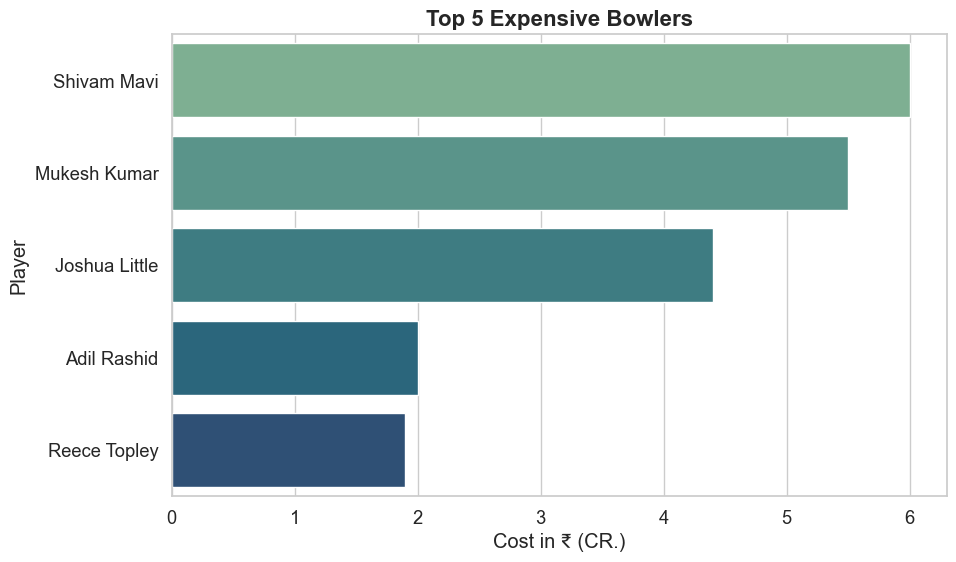

In [33]:
sns.set_theme(style='whitegrid', font_scale=1.2)

plt.figure(figsize=(10, 6))  
#sns.barplot(x='Cost in Cr', y='Name', data=top_5_expensive_bowlers, dodge = False, palette = 'crest')
sns.barplot(
    data=top_5_expensive_bowlers,
    x='Cost in Cr',
    y='Name',
    hue='Name',          # assign hue
    palette='crest',
    dodge=False,
    legend=False         # suppress legend if not needed
)


plt.xlabel('Cost in ₹ (CR.)')
plt.ylabel('Player')
plt.title('Top 5 Expensive Bowlers', fontweight='bold', fontsize=16)
plt.show()

### Q6) Did all teams purchase players to their full capacity ?




In [34]:
data = data[data['Team'] != 'Unsold']

In [35]:
team_counts = data['Team'].value_counts()

In [36]:
data_team_counts = pd.DataFrame(team_counts)
data_team_counts

,count
Team,
Sunrisers Hyderabad,13
Lucknow Super Giants,10
Rajasthan Royals,9
Kolkata Knight Riders,8
Mumbai Indians,8
Gujarat Titans,7
Chennai Super Kings,7
Royal Challengers Banglore,7
Punjab Super Kings,6
